# just_tx XDP：火焰图 span 逐项说明

本笔记只解释 **kind-t Trace** 导出的两张时间序图（`path-rx` / `path-tx`），不讲丢包扫速。

- **不是**经典 flame graph（按累计时间合并同栈）：这里是 **chronological flame chart**——x = episode 内 `t_us`，y = 嵌套深度。
- 图上很短的竖条多半是 **point stamp**（宽≈1µs 渲染下限），不是“函数超快”。
- 空白 = **该时段没有 stamp**（等空口、等下一包、未埋点），不是未计时的 CPU。

采集：`run = ["dev"]` → TR3000 `./xpost-test` → scp `/tmp/xpost-dev-flame.report` → `target/dev-flame.report` → `pixi run python -m utils.export_flame_svg`。


### path-rx — `just_tx-xdp-dev-path-rx.flame.png`

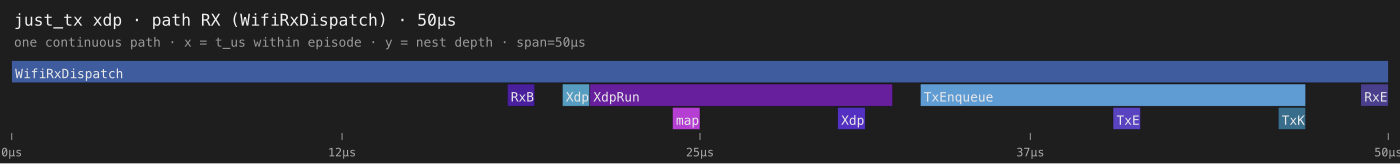

### path-tx — `just_tx-xdp-dev-path-tx.flame.png`

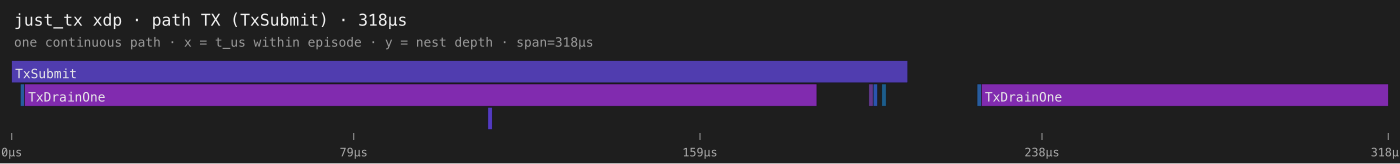

In [1]:
from IPython.display import Image, Markdown, display
from pathlib import Path

target = Path("..").resolve() / "target"


def show_flame(kind: str) -> Path | None:
    preferred = target / f"just_tx-xdp-dev-path-{kind}.flame.png"
    if preferred.is_file():
        p = preferred
    else:
        cands = sorted(target.glob(f"just_tx-xdp-*-path-{kind}.flame.png"))
        p = cands[-1] if cands else None
    if p is None:
        display(Markdown(f"_缺 path-{kind}.flame.png：先 export_flame_svg_"))
        return None
    display(Markdown(f"### path-{kind} — `{p.name}`"))
    display(Image(filename=str(p)))
    return p

rx_png = show_flame("rx")
tx_png = show_flame("tx")

## 两条路径怎么拆开的

一帧回发在固件里是 **异步两段**：

1. **path-rx**（Wi-Fi RX 回调上下文）：收包 → 跑冷表 → 决策 `XDP_TX` → **入 TX ring + kick**，然后回调返回。
2. **path-tx**（TX task / 稍后）：从 ring 取出 → `esp_wifi_internal_tx_by_ref` → 交给驱动；空口完成可能更晚（`TxCompleted`）。

```
path-rx   WifiRxDispatch
            ├─ RxBegin … XdpBegin
            ├─ XdpRun ── map_lookup …
            ├─ TxEnqueue ── TxEnq / TxKick
            └─ RxEnd
                 │ kick
                 ▼
path-tx   TxSubmit
            ├─ TxSubBegin
            ├─ TxDrainOne   ← esp_wifi_internal_tx_by_ref
            ├─ TxBlock / TxSubmitted / TxNoRetain …
            └─ (窗外) TxCompleted …
```

导出故意 **不画 overview**：跨包静默会把单次路径压成细线，不利于读 span。


## path-rx：每个名字是什么

下列按图上大致时间顺序。条带 = **闭区间 span**（`SpanBegin`/`SpanEnd` 或 helper enter/leave）；竖条 = **point**。

### `WifiRxDispatch`（span · 根）

- **埋点**：`esp-radio` `xdp_dispatch` 入口 `Span::enter(WifiRxDispatch)`，函数返回时结束。
- **含义**：一次 STA/AP RX 软件分发——拿 buffer、调 XDP、按 Pass/Drop/Tx 处置。
- **读图**：整段 RX 情节的外壳；其内才是真正干活的子 span。

### `RxBegin`（point；图上常缩成 `RxB`）

- **埋点**：`rx_packets` / Trace `RxBegin`（软件 RX 入口附近）。
- **含义**：“这一帧开始进我们的 RX 观测面”。
- **读图**：几乎总是落在 `WifiRxDispatch` 内、靠前的竖条。

### `XdpBegin` / `XdpEnd`（point；常缩成 `Xdp`）

- **埋点**：调用 / 离开租约镜像前后（与 `XdpRun` 对齐）。
- **含义**：点戳版“进/出 XDP 镜像”；时长信息以 **`XdpRun` span** 为准。
- **读图**：`XdpBegin` 贴在 `XdpRun` 左缘，`XdpEnd` 贴右缘；窄条不要当成独立重活。

### `XdpRun`（span）

- **埋点**：`Span::enter(XdpRun)` 包住 `prog.run(frame)`。
- **含义**：冷表 XDP 镜像实际执行（解析 / 改写 / 返回 action）。
- **读图**：RX 里通常最长的“算包”段；其内可再嵌 helper。

### `map_lookup`（helper span；图上常缩成 `map`）

- **埋点**：`HelperEnter`/`HelperLeave`，`arg0` = BPF helper id（lookup=1）。
- **含义**：镜像里一次 `bpf_map_lookup_elem`（其它 helper 会显示成 `map_update` / `csum_diff` 等）。
- **读图**：嵌在 `XdpRun` 下的短横条 = 该次 helper 墙钟。

### `TxEnqueue`（span）

- **埋点**：TX 路径 claim token + 入 ring 的那段 `Span::enter(TxEnqueue)`（仍在 **RX 回调**里）。
- **含义**：`XDP_TX` 后把帧挂到 TX ring，**还没有**调用 `esp_wifi_internal_tx_by_ref`。
- **读图**：紧挨 `XdpRun` 之后；“决定发”和“真正交给 Wi-Fi 驱动”在这里切开。

### `TxEnq`（point；常缩成 `TxE`）

- **埋点**：`tx_enq()` —— ring 入队成功。
- **含义**：队列里多了一帧待提交。
- **读图**：落在 `TxEnqueue` 内的竖条。

### `TxKick`（point；常缩成 `TxK`）

- **埋点**：`tx_kick()` —— 唤醒 / 通知 TX task 去 drain。
- **含义**：path-rx 与 path-tx 的衔接信号；之后 RX 回调可以结束。
- **读图**：常在 `TxEnqueue` 末尾；**不等于**空口已发出。

### `RxEnd`（point；常缩成 `RxE`）

- **埋点**：`rx_end()` —— 本轮 RX 分发收尾。
- **含义**：`WifiRxDispatch` 即将退出。
- **读图**：path-rx 最右侧竖条。

### 本图一般不会出现、但同族相关

| 名 | 含义 |
|---|---|
| `RxDelivered` | Pass：帧进协议栈队列 |
| `RxDiscarded` | Drop：帧已释放 |
| `RxOverflow` | Pass 队列满 |
| `TxEnqFailClaim` / `TxEnqFailRing` | 入队失败（claim / ring 满） |


## path-tx：每个名字是什么

TX task 与 RX 回调 **不同上下文**；时间轴从该次提交 episode 的第一个 TX stamp 重新归零。

### `TxSubmit`（span · 根，新加）

- **埋点**：`poll()` 里一次提交尝试外包 `Span::enter(TxSubmit)`（reserve → `tx_by_ref` → submitted/failed）。
- **含义**：“这一轮尝试把 ring 头交给驱动”的整段墙钟。
- **读图**：外层长条；内部应嵌 `TxDrainOne` 与若干 point。若报告来自旧固件、没有此 site，导出会退回以 `TxDrainOne` 为根。

### `TxSubBegin`（point）

- **埋点**：`tx_submission_begin()` —— 即将调用 `tx_by_ref`。
- **含义**：提交开始标记（与 Aggregate 的 submission 对齐）。
- **读图**：`TxSubmit` 内、`TxDrainOne` 左缘附近的竖条。

### `TxDrainOne`（span）

- **埋点**：`Span::enter(TxDrainOne)` **仅包住** `esp_wifi_internal_tx_by_ref(...)`。
- **含义**：单次把零拷贝 buffer 交给 Wi-Fi 驱动的同步调用。耗时长通常表示 **堵在驱动/固件 API 里**，不是 XDP 镜像。
- **读图**：path-tx 里往往最粗最长；其内部目前几乎没有更细 stamp（API 黑盒）。若同一张图里出现 **第二条独立的 `TxDrainOne`**（不在当前 `TxSubmit` 下），多半是 **同 episode 时间窗扫进了另一次 drain**（下一帧 / 下一轮 poll），不是同一次 `by_ref` 的“第二阶段”。

### `TxBlock`（point）

- **埋点**：`tx_block()` —— `by_ref` 返回且非 `NO_MEM` 之后、出队前后的观测点。
- **含义**：本轮提交路径上“阻塞/等待语义”相关的点戳（与 Aggregate `tx_block` 同名族）；**不是**又一次 `by_ref`。

### `TxSubmitted`（point）

- **埋点**：`tx_submitted()` —— `tx_by_ref` 返回 `ESP_OK`。
- **含义**：驱动已接受该帧；**空口未必完成**。

### `TxNoRetain`（point）

- **埋点**：`tx_no_retain()` —— OK 但 token 未被驱动多持一引用。
- **含义**：零拷贝 retain 路径未走成；与 inflight/`NEED_DONE` 记账有关，便于区分“已提交但仍 pin buffer” vs “立刻可释放语义”。

### `TxFailed` / `TxNomemWait`（point）

- **`TxFailed`**：`tx_by_ref` 失败（非 OK）。
- **`TxNomemWait`**：`ESP_ERR_NO_MEM` —— 驱动暂不能收，本轮 `poll` 退出等待后续 kick。

### `TxCompleted`（point）

- **埋点**：`on_tx_done` → `tx_completed(ok)`。
- **含义**：空口 TX done（成功/失败）。常落在 **`TxSubmit` 结束之后**（异步）；导出用短 trail 窗把它扫进同一张 path-tx。
- **读图**：若出现在长间隔之后，说明大部分时间在等射频/驱动完成，而不是又在跑 XDP。

### `TxPoll` / `TxCapWait`（point）

- **`TxPoll`**：TX task 进入 `poll()`。
- **`TxCapWait`**：软 inflight cap 已满，本轮不能再 `by_ref`。

### 本图少见 / 故障路径

| 名 | 含义 |
|---|---|
| `TxFailBadBuf` / `TxFailToken` | 坏缓冲 / token 问题 |
| `TxFlush` | 冲刷路径 |
| `TxGrpSrc` | 组播/源相关分支 |
| `TxDrainBatch` | 旧批量 site（保留编号，当前不用） |


## 对照当前两张图怎么读（检查清单）

**path-rx（约数十 µs）**

1. 最外层应是整段 `WifiRxDispatch`。
2. 中段 `XdpRun` ≈ 镜像 CPU；其内短条 = helper（如 `map_lookup`）。
3. 后段 `TxEnqueue` ≈ 入队 + `TxKick`；到此 **回发尚未保证上空气**。
4. 末尾 `RxEnd` 后回调返回；真正 `tx_by_ref` 在 path-tx。

**path-tx（可达数百 µs）**

1. 外层 `TxSubmit` 包住一次提交尝试。
2. 内部大块 `TxDrainOne` = 堵在 `esp_wifi_internal_tx_by_ref`。
3. 右缘细竖条：`TxBlock` / `TxSubmitted` / `TxNoRetain` 等收尾点戳。
4. 若另有独立 `TxDrainOne`：优先怀疑 **episode 拼窗扫进了另一次 drain**，不要解读成同一次调用的内部阶段。
5. `TxCompleted` 若很晚：瓶颈在提交之后的空口完成，不在 XDP。

**常见误读**

- 把 point 的渲染宽度当成真实耗时。
- 把 path-rx 的 `TxEnqueue` 当成空口发送。
- 把两张图的 0µs 当成同一绝对时刻（各自 episode 归零）。
- 期望 HAL `App*` 与 XDP `Tx*` 一一对齐（异步模型不同，本导出已排除 App 环）。


## 术语速查（全名）

| 图上可能缩写 | 全名 | 类型 |
|---|---|---|
| — | `WifiRxDispatch` | span |
| `RxB` | `RxBegin` | point |
| `Xdp` | `XdpBegin` / `XdpEnd` | point |
| — | `XdpRun` | span |
| `map` | `map_lookup`（或其它 helper） | helper span |
| — | `TxEnqueue` | span |
| `TxE` | `TxEnq` | point |
| `TxK` | `TxKick` | point |
| `RxE` | `RxEnd` | point |
| — | `TxSubmit` | span |
| — | `TxSubBegin` | point |
| — | `TxDrainOne` | span |
| — | `TxBlock` / `TxSubmitted` / `TxNoRetain` / `TxCompleted` | point |

实现索引：`ProfSite` → `xpost-type`；point kind → `xpost::ext::perf::trace::EventKind`；埋点 → `esp-radio` `xdp_dispatch` / `xdp/tx.rs`。
